In [1]:
!pip install -q kagglehub
from google.colab import files
print("Choose your kaggle.json:")
files.upload()
!mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
print("Key set.")

Choose your kaggle.json:


Saving kaggle.json to kaggle.json
Key set.


In [2]:
import kagglehub
pv_path = kagglehub.dataset_download("emmarex/plantdisease")                 # lab photos (PlantVillage)
!git clone -q --depth 1 https://github.com/pratikkayal/PlantDoc-Dataset.git   # real-world photos (PlantDoc)
print("Lab data at:", pv_path, "| Real-world data in PlantDoc-Dataset/")

Using Colab cache for faster access to the 'plantdisease' dataset.
Lab data at: /kaggle/input/plantdisease | Real-world data in PlantDoc-Dataset/


In [3]:
from pathlib import Path
from PIL import Image
import numpy as np, hashlib, random
Image.MAX_IMAGE_PIXELS = None

# 9 classes that exist in BOTH datasets (Target Spot has no real-world match, so it's dropped)
KEYS  = ['bacterial', 'early', 'late', 'mold', 'septoria', 'spider', 'yellow', 'mosaic']
SHORT = ['Bacterial spot', 'Early blight', 'Late blight', 'Leaf mold', 'Septoria',
         'Spider mites', 'Yellow leaf curl', 'Mosaic virus', 'Healthy']
IMG_EXT = {'.jpg', '.jpeg', '.png', '.webp', '.bmp'}

def load(p):
    img = Image.open(p)
    img.draft('RGB', (512, 512))      # opens big photos faster
    img = img.convert('RGB')
    img.thumbnail((512, 512))
    return img

def match_class(folder_name):
    n = folder_name.lower()
    if 'tomato' not in n or 'target' in n:
        return None
    for i, k in enumerate(KEYS):
        if k in n:
            return i
    return 8   # healthy: 'Tomato_healthy' (lab) / 'Tomato leaf' (real-world)

def collect(root, by_name):
    groups = {}
    for folder in Path(root).rglob('*'):
        if folder.is_dir():
            imgs = sorted(f for f in folder.iterdir() if f.suffix.lower() in IMG_EXT)
            if imgs:
                groups[folder.name if by_name else str(folder)] = (folder.name, imgs)
    data = {c: [] for c in range(9)}
    for name, imgs in groups.values():
        c = match_class(name)
        if c is not None:
            data[c] += imgs
    return data

lab = collect(pv_path, by_name=True)
field_raw = collect('PlantDoc-Dataset', by_name=False)   # PlantDoc's train AND test folders

# Clean real-world photos: drop exact duplicates and files that won't open
seen, field, dups, bad = set(), {c: [] for c in range(9)}, 0, 0
for c in range(9):
    for p in field_raw[c]:
        h = hashlib.md5(p.read_bytes()).hexdigest()
        if h in seen:
            dups += 1; continue
        try:
            load(p)
        except Exception:
            bad += 1; continue
        seen.add(h); field[c].append(p)

print(f"{'Class':<18}{'Lab':>8}{'Real-world':>12}")
for c in range(9):
    print(f"{SHORT[c]:<18}{len(lab[c]):>8}{len(field[c]):>12}")
print(f"{'TOTAL':<18}{sum(len(v) for v in lab.values()):>8}{sum(len(v) for v in field.values()):>12}")
print(f"\nCleaning: removed {dups} duplicate and {bad} unreadable real-world images")
print("Real-world folders used:", sorted({p.parent.name for v in field.values() for p in v}))

Class                  Lab  Real-world
Bacterial spot        2127         110
Early blight          1000          88
Late blight           1909         111
Leaf mold              952          91
Septoria              1771         149
Spider mites          1676           2
Yellow leaf curl      3208          75
Mosaic virus           373          54
Healthy               1591          63
TOTAL                14607         743

Cleaning: removed 3 duplicate and 0 unreadable real-world images
Real-world folders used: ['Tomato Early blight leaf', 'Tomato Septoria leaf spot', 'Tomato leaf', 'Tomato leaf bacterial spot', 'Tomato leaf late blight', 'Tomato leaf mosaic virus', 'Tomato leaf yellow virus', 'Tomato mold leaf', 'Tomato two spotted spider mites leaf']


In [4]:
from sklearn.model_selection import train_test_split
random.seed(42)
paths, labels = [], []
for c in range(9):
    imgs = lab[c][:]
    random.shuffle(imgs)
    keep = imgs[:int(len(imgs) * 0.25)]   # use 25% of lab photos so it runs fast
    paths += keep; labels += [c] * len(keep)

train_p, labtest_p, y_train, y_lab = train_test_split(
    paths, labels, test_size=0.3, stratify=labels, random_state=42)
field_p = [p for c in range(9) for p in field[c]]
y_field = [c for c in range(9) for p in field[c]]
y_train, y_lab, y_field = map(np.array, (y_train, y_lab, y_field))
print(f"Train (lab): {len(train_p)} | Lab test: {len(labtest_p)} | Real-world test: {len(field_p)}")

Train (lab): 2554 | Lab test: 1095 | Real-world test: 743


In [5]:
import torch, torchvision
device = 'cuda' if torch.cuda.is_available() else 'cpu'
weights = torchvision.models.EfficientNet_B0_Weights.DEFAULT
net = torchvision.models.efficientnet_b0(weights=weights)   # pretrained on ImageNet
net.classifier = torch.nn.Identity()                         # remove its original output layer
net = net.eval().to(device)
prep = weights.transforms()

def cnn_features(paths, bs=64):
    out = []
    for i in range(0, len(paths), bs):
        x = torch.stack([prep(load(p)) for p in paths[i:i+bs]]).to(device)
        with torch.no_grad():
            out.append(net(x).cpu())
    return torch.cat(out).numpy()

print("Using:", device)
F_train, F_lab, F_field = cnn_features(train_p), cnn_features(labtest_p), cnn_features(field_p)
print("Features per image:", F_train.shape[1])

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 132MB/s] 


Using: cuda
Features per image: 1280


In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# LeafGuard: a simple classifier trained on the CNN features (lab photos only)
cnn = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight='balanced'))
cnn.fit(F_train, y_train)

# Classical baseline (no deep learning): color histograms + Random Forest
def color_hist(p, bins=16):
    hsv = np.array(load(p).resize((128, 128)).convert('HSV'))
    h = np.concatenate([np.histogram(hsv[..., ch], bins=bins, range=(0, 256))[0] for ch in range(3)])
    return h / h.sum()

H_train = np.array([color_hist(p) for p in train_p])
H_lab   = np.array([color_hist(p) for p in labtest_p])
H_field = np.array([color_hist(p) for p in field_p])
rf = RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42, n_jobs=-1)
rf.fit(H_train, y_train)
print("Both models trained.")

Both models trained.


Same cases for every method: 1095 lab photos | 743 real-world photos


,Method,Lab acc,Lab macro-F1,Real-world acc,Real-world macro-F1,Field Retention Score
0,Majority class (floor),0.220,0.040,0.101,0.020,NaN
1,Color histogram + Random Forest,0.901,0.890,0.135,0.076,0.085
2,LeafGuard (EfficientNet-B0 + LogReg),0.936,0.921,0.240,0.154,0.167


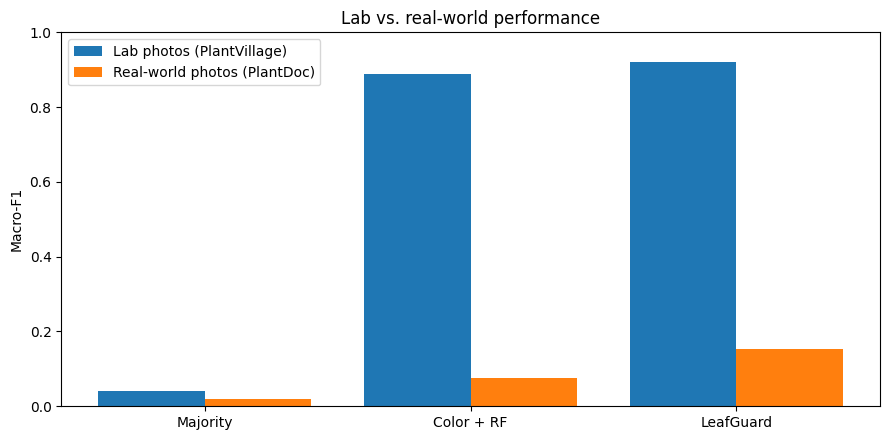

In [7]:
import pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score

def evaluate(y, pred):
    return (accuracy_score(y, pred),
            f1_score(y, pred, labels=np.unique(y), average='macro', zero_division=0))

majority = np.bincount(y_train).argmax()
methods = {
    'Majority class (floor)': (np.full(len(y_lab), majority), np.full(len(y_field), majority)),
    'Color histogram + Random Forest': (rf.predict(H_lab), rf.predict(H_field)),
    'LeafGuard (EfficientNet-B0 + LogReg)': (cnn.predict(F_lab), cnn.predict(F_field)),
}
rows = []
for name, (pl, pf) in methods.items():
    la, lf = evaluate(y_lab, pl)
    fa, ff = evaluate(y_field, pf)
    frs = ff / lf if not name.startswith('Majority') else np.nan
    rows.append([name, la, lf, fa, ff, frs])
table = pd.DataFrame(rows, columns=['Method', 'Lab acc', 'Lab macro-F1',
                                    'Real-world acc', 'Real-world macro-F1', 'Field Retention Score'])
print(f"Same cases for every method: {len(y_lab)} lab photos | {len(y_field)} real-world photos")
display(table.round(3))
table.to_csv('results_table.csv', index=False)

x = np.arange(len(table))
plt.figure(figsize=(9, 4.5))
plt.bar(x - 0.2, table['Lab macro-F1'], 0.4, label='Lab photos (PlantVillage)')
plt.bar(x + 0.2, table['Real-world macro-F1'], 0.4, label='Real-world photos (PlantDoc)')
plt.xticks(x, ['Majority', 'Color + RF', 'LeafGuard'])
plt.ylabel('Macro-F1'); plt.ylim(0, 1); plt.legend()
plt.title('Lab vs. real-world performance')
plt.tight_layout(); plt.savefig('results_chart.png', dpi=120); plt.show()

In [8]:
proba = cnn.predict_proba(F_field)
conf, pred = proba.max(axis=1), proba.argmax(axis=1)   # Trust Score = confidence in top answer
correct = pred == y_field
lab_proba = cnn.predict_proba(F_lab)
lab_correct = lab_proba.argmax(axis=1) == y_lab

print(f"Lab photos:        avg trust {lab_proba.max(axis=1).mean():.1%} | actual accuracy {lab_correct.mean():.1%}")
print(f"Real-world photos: avg trust {conf.mean():.1%} | actual accuracy {correct.mean():.1%}\n")
for t in [0.5, 0.7, 0.9]:
    trusted = conf >= t
    acc_t = correct[trusted].mean() if trusted.any() else float('nan')
    acc_f = correct[~trusted].mean() if (~trusted).any() else float('nan')
    print(f"Trust >= {t:.0%}: {trusted.sum()} trusted ({trusted.mean():.0%}), accuracy {acc_t:.1%} | "
          f"{(~trusted).sum()} flagged, accuracy {acc_f:.1%}")

Lab photos:        avg trust 96.1% | actual accuracy 93.6%
Real-world photos: avg trust 87.5% | actual accuracy 24.0%

Trust >= 50%: 709 trusted (95%), accuracy 24.1% | 34 flagged, accuracy 20.6%
Trust >= 70%: 616 trusted (83%), accuracy 24.2% | 127 flagged, accuracy 22.8%
Trust >= 90%: 474 trusted (64%), accuracy 25.9% | 269 flagged, accuracy 20.4%


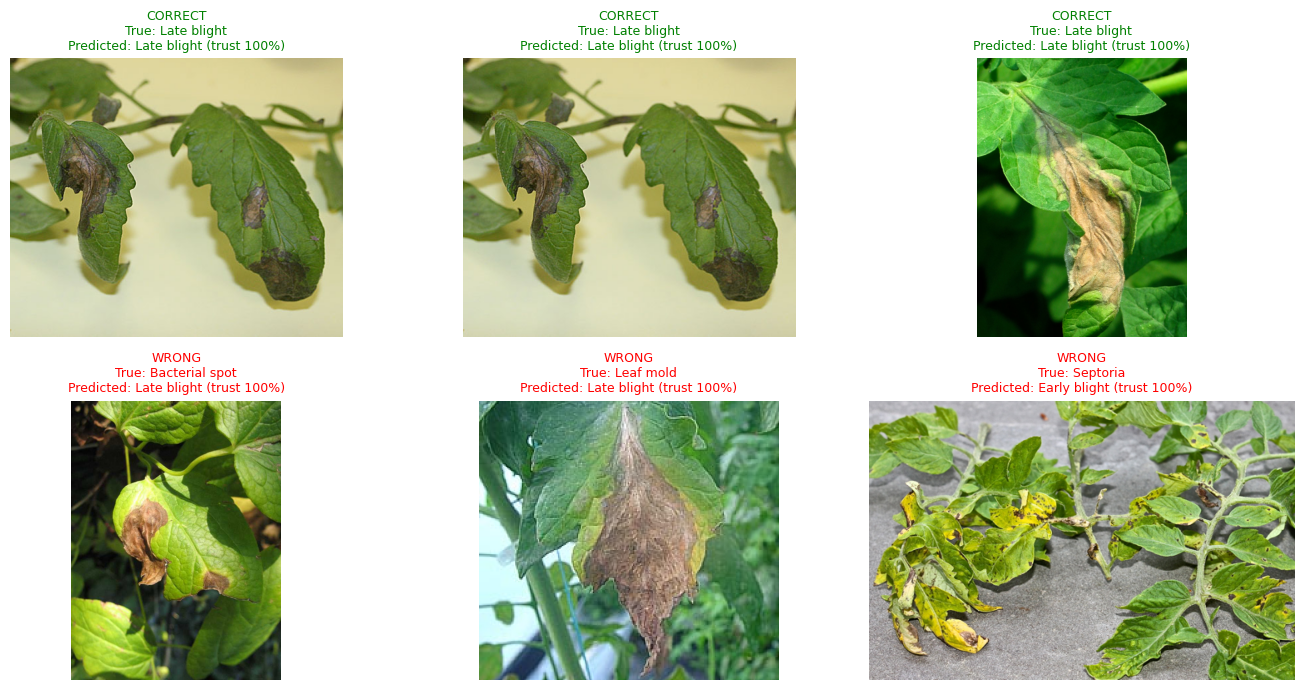

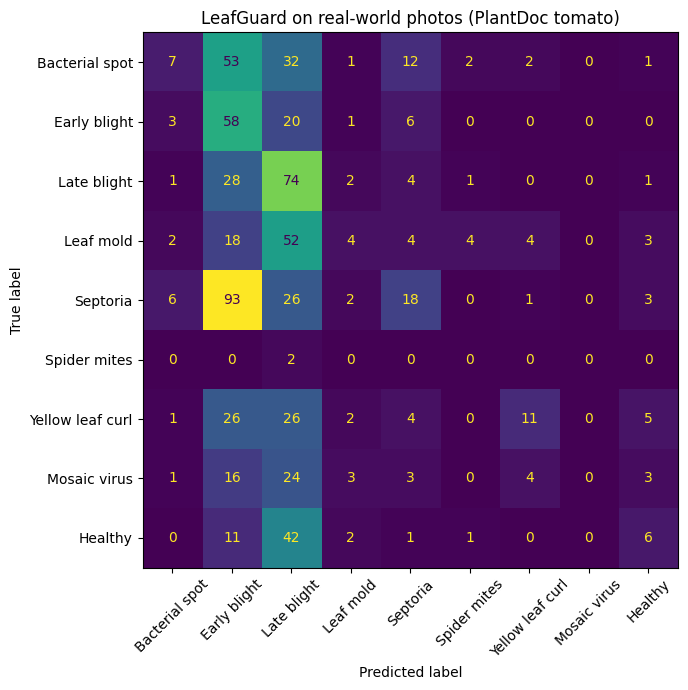

                  precision    recall  f1-score   support

  Bacterial spot       0.33      0.06      0.11       110
    Early blight       0.19      0.66      0.30        88
     Late blight       0.25      0.67      0.36       111
       Leaf mold       0.24      0.04      0.07        91
        Septoria       0.35      0.12      0.18       149
    Spider mites       0.00      0.00      0.00         2
Yellow leaf curl       0.50      0.15      0.23        75
    Mosaic virus       0.00      0.00      0.00        54
         Healthy       0.27      0.10      0.14        63

        accuracy                           0.24       743
       macro avg       0.24      0.20      0.15       743
    weighted avg       0.28      0.24      0.18       743



In [9]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

# Top row: most confident CORRECT real-world photos. Bottom row: most confident WRONG ones.
right, wrong = np.where(correct)[0], np.where(~correct)[0]
pick = list(right[np.argsort(-conf[right])][:3]) + list(wrong[np.argsort(-conf[wrong])][:3])
plt.figure(figsize=(14, 7))
for k, i in enumerate(pick):
    plt.subplot(2, 3, k + 1)
    plt.imshow(load(field_p[i]))
    plt.title(f"{'CORRECT' if correct[i] else 'WRONG'}\nTrue: {SHORT[y_field[i]]}\n"
              f"Predicted: {SHORT[pred[i]]} (trust {conf[i]:.0%})",
              fontsize=9, color='green' if correct[i] else 'red')
    plt.axis('off')
plt.tight_layout(); plt.savefig('field_examples.png', dpi=120); plt.show()

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(y_field, pred, labels=list(range(9)), display_labels=SHORT,
                                        xticks_rotation=45, colorbar=False, ax=ax)
ax.set_title('LeafGuard on real-world photos (PlantDoc tomato)')
plt.tight_layout(); plt.savefig('field_confusion.png', dpi=120); plt.show()

print(classification_report(y_field, pred, labels=list(range(9)), target_names=SHORT, zero_division=0))

LeafGuard + augmentation trained on 7662 lab images

=== TABLE 1 ===
                         Method  Lab acc  Lab macro-F1  Real acc  Real macro-F1   FRS
         Majority class (floor)    0.220         0.040     0.101          0.020   NaN
Color histogram + Random Forest    0.901         0.890     0.135          0.076 0.085
                      LeafGuard    0.936         0.921     0.240          0.154 0.167
       LeafGuard + augmentation    0.932         0.920     0.249          0.170 0.185

=== TRUST SCORE ===
LeafGuard
  Lab: avg trust 96.1% | accuracy 93.6% | ECE 0.026 | AUROC 0.923
  Real: avg trust 87.5% | accuracy 24.0% | ECE 0.636 | AUROC 0.592
    trust >= 50%: 709 trusted (24.1% accurate) | 34 flagged (20.6% accurate)
    trust >= 70%: 616 trusted (24.2% accurate) | 127 flagged (22.8% accurate)
    trust >= 90%: 474 trusted (25.9% accurate) | 269 flagged (20.4% accurate)
LeafGuard + augmentation
  Lab: avg trust 97.6% | accuracy 93.2% | ECE 0.043 | AUROC 0.914
  Real: avg t

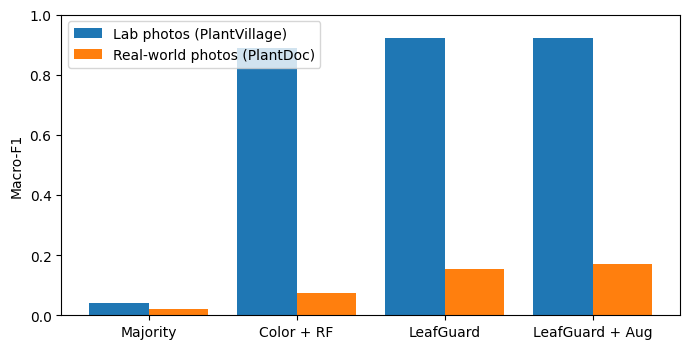

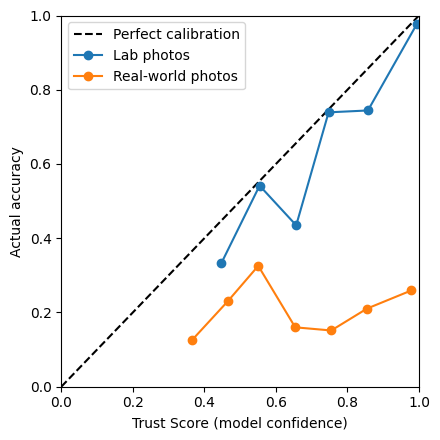

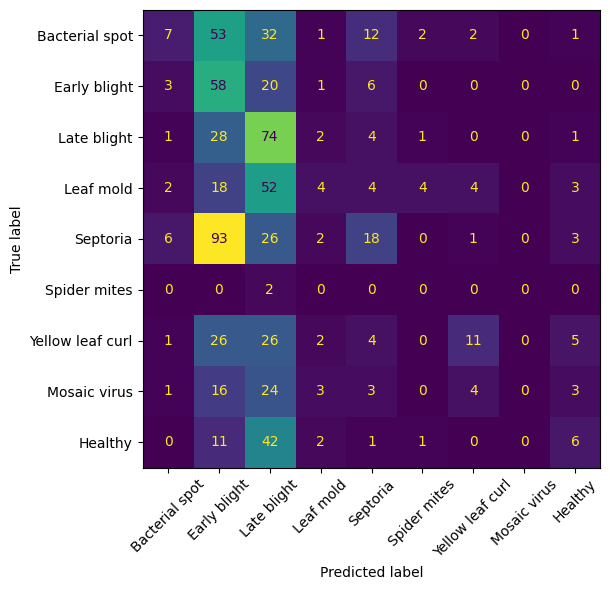

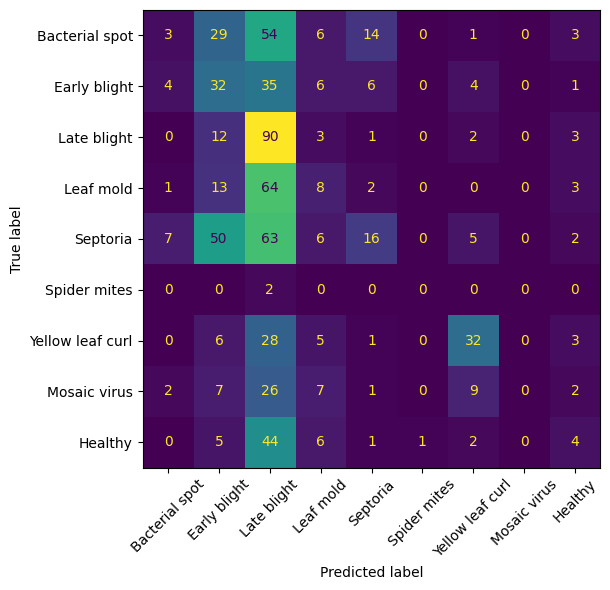

In [10]:
import importlib.metadata as md, sys
from torchvision import transforms as T
from sklearn.metrics import roc_auc_score, classification_report, ConfusionMatrixDisplay

#altered copies of the LAB training photos only
torch.manual_seed(42); random.seed(42); np.random.seed(42)
augment = T.Compose([
    T.RandomResizedCrop(256, scale=(0.3, 1.0)),                             # zoom and framing
    T.RandomHorizontalFlip(),
    T.RandomRotation(25),                                                    # camera angle
    T.ColorJitter(brightness=0.5, contrast=0.5, saturation=0.5, hue=0.05),  # lighting and color
    T.RandomApply([T.GaussianBlur(9, sigma=(0.5, 3.0))], p=0.5),             # focus blur
])
K = 2  #altered copies per training photo

def cnn_features_aug(paths, bs=64):
    out = []
    for i in range(0, len(paths), bs):
        x = torch.stack([prep(augment(load(p))) for p in paths[i:i+bs]]).to(device)
        with torch.no_grad():
            out.append(net(x).cpu())
    return torch.cat(out).numpy()

F_aug = np.concatenate([cnn_features_aug(train_p) for _ in range(K)])
cnn_aug = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight='balanced'))
cnn_aug.fit(np.concatenate([F_train, F_aug]), np.concatenate([y_train] * (K + 1)))
print(f"LeafGuard + augmentation trained on {len(y_train) * (K + 1)} lab images\n")

#Four methods on the same 1,095 lab and 743 real world photos
def evaluate(y, pred):
    return (accuracy_score(y, pred),
            f1_score(y, pred, labels=np.unique(y), average='macro', zero_division=0))

majority = np.bincount(y_train).argmax()
methods = {
    'Majority class (floor)':          (np.full(len(y_lab), majority), np.full(len(y_field), majority)),
    'Color histogram + Random Forest': (rf.predict(H_lab), rf.predict(H_field)),
    'LeafGuard':                       (cnn.predict(F_lab), cnn.predict(F_field)),
    'LeafGuard + augmentation':        (cnn_aug.predict(F_lab), cnn_aug.predict(F_field)),
}
rows = []
for name, (pl, pf) in methods.items():
    la, lf = evaluate(y_lab, pl)
    fa, ff = evaluate(y_field, pf)
    rows.append([name, la, lf, fa, ff, np.nan if name.startswith('Majority') else ff / lf])
table = pd.DataFrame(rows, columns=['Method', 'Lab acc', 'Lab macro-F1',
                                    'Real acc', 'Real macro-F1', 'FRS'])
table.to_csv('results_table.csv', index=False)
print("=== TABLE 1 ===")
print(table.round(3).to_string(index=False))

#Trust Score: determining if confidence tell right answers from wrong ones?
def ece(c, ok, bins=10):  #The average gap between confidence and actual accuracy
    idx = np.minimum((c * bins).astype(int), bins - 1)
    return sum(abs(ok[idx == b].mean() - c[idx == b].mean()) * (idx == b).mean()
               for b in range(bins) if (idx == b).any())

print("\n=== TRUST SCORE ===")
trust = {}
for name, model in [('LeafGuard', cnn), ('LeafGuard + augmentation', cnn_aug)]:
    print(name)
    for split, F, y in [('Lab', F_lab, y_lab), ('Real', F_field, y_field)]:
        p = model.predict_proba(F)
        c, ok = p.max(axis=1), p.argmax(axis=1) == y
        trust[(name, split)] = (c, ok)
        auroc = roc_auc_score(ok, c) if 0 < ok.mean() < 1 else float('nan')
        print(f"  {split}: avg trust {c.mean():.1%} | accuracy {ok.mean():.1%} | "
              f"ECE {ece(c, ok):.3f} | AUROC {auroc:.3f}")
        if split == 'Real':
            for t in [0.5, 0.7, 0.9]:
                m = c >= t
                a_t = ok[m].mean() if m.any() else float('nan')
                a_f = ok[~m].mean() if (~m).any() else float('nan')
                print(f"    trust >= {t:.0%}: {m.sum()} trusted ({a_t:.1%} accurate) | "
                      f"{(~m).sum()} flagged ({a_f:.1%} accurate)")

#The "blight collapse"
print("\n=== REAL-WORLD PREDICTION PATTERNS ===")
for name, model in [('LeafGuard', cnn), ('LeafGuard + augmentation', cnn_aug)]:
    pr = model.predict(F_field)
    print(f"{name}: {np.isin(pr, [1, 2]).mean():.1%} predicted early/late blight | "
          f"healthy called late blight: {((y_field == 8) & (pr == 2)).sum()} of {(y_field == 8).sum()} | "
          f"mosaic predicted {(pr == 7).sum()} times")

#Per-class real-world results
for name, model in [('LeafGuard', cnn), ('LeafGuard + augmentation', cnn_aug)]:
    print(f"\n=== PER-CLASS REAL-WORLD RESULTS: {name} ===")
    print(classification_report(y_field, model.predict(F_field), labels=list(range(9)),
                                target_names=SHORT, zero_division=0, digits=3))

#Exact software versions
with open('requirements.txt', 'w') as f:
    for pkg in ['torch', 'torchvision', 'scikit-learn', 'numpy', 'pandas',
                'matplotlib', 'Pillow', 'kagglehub']:
        try:
            f.write(f"{pkg}=={md.version(pkg)}\n")
        except md.PackageNotFoundError:
            pass
print("=== ENVIRONMENT ===")
print(open('requirements.txt').read())
print("Python", sys.version.split()[0], "| GPU:",
      torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (CPU)")

#Figures
x = np.arange(len(table))
plt.figure(figsize=(7, 3.6))
plt.bar(x - 0.2, table['Lab macro-F1'], 0.4, label='Lab photos (PlantVillage)')
plt.bar(x + 0.2, table['Real macro-F1'], 0.4, label='Real-world photos (PlantDoc)')
plt.xticks(x, ['Majority', 'Color + RF', 'LeafGuard', 'LeafGuard + Aug'])
plt.ylabel('Macro-F1'); plt.ylim(0, 1); plt.legend()
plt.tight_layout(); plt.savefig('results_chart.png', dpi=200); plt.show()

plt.figure(figsize=(4.5, 4.5))
plt.plot([0, 1], [0, 1], 'k--', label='Perfect calibration')
for split, label in [('Lab', 'Lab photos'), ('Real', 'Real-world photos')]:
    c, ok = trust[('LeafGuard', split)]
    idx = np.minimum((c * 10).astype(int), 9)
    keep = [b for b in range(10) if (idx == b).sum() >= 5]
    plt.plot([c[idx == b].mean() for b in keep], [ok[idx == b].mean() for b in keep], 'o-', label=label)
plt.xlabel('Trust Score (model confidence)'); plt.ylabel('Actual accuracy')
plt.xlim(0, 1); plt.ylim(0, 1); plt.legend()
plt.tight_layout(); plt.savefig('reliability.png', dpi=200); plt.show()

for fname, model in [('field_confusion.png', cnn), ('field_confusion_aug.png', cnn_aug)]:
    fig, ax = plt.subplots(figsize=(7, 6))
    ConfusionMatrixDisplay.from_predictions(y_field, model.predict(F_field), labels=list(range(9)),
                                            display_labels=SHORT, xticks_rotation=45,
                                            colorbar=False, ax=ax)
    plt.tight_layout(); plt.savefig(fname, dpi=200); plt.show()

True label: Bacterial spot


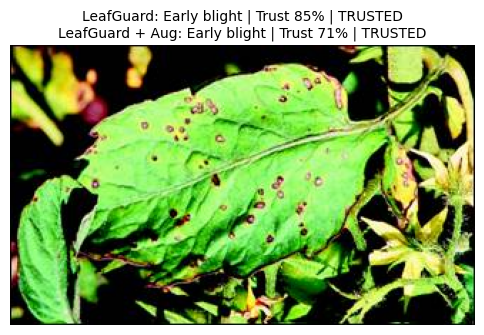

In [11]:
def diagnose(path):
    f = cnn_features([Path(path)])
    lines = []
    for name, model in [('LeafGuard', cnn), ('LeafGuard + Aug', cnn_aug)]:
        p = model.predict_proba(f)[0]
        k = p.argmax()
        verdict = 'TRUSTED' if p[k] >= 0.7 else 'LOW TRUST: retake photo or ask an expert'
        lines.append(f"{name}: {SHORT[k]} | Trust {p[k]:.0%} | {verdict}")
    plt.figure(figsize=(6, 6)); plt.imshow(load(Path(path))); plt.axis('off')
    plt.title('\n'.join(lines), fontsize=10); plt.show()

i = 0   #any real world test photo from 0 to 742
print("True label:", SHORT[y_field[i]])
diagnose(field_p[i])


=== EXACT DUPLICATES (PlantDoc) ===
3 duplicate groups, 1 with conflicting labels
  conflicting: [('Bacterial spot', 'tomato_V8.jpg'), ('Septoria', 'tomato_V8.jpg')]

=== NEAR-DUPLICATE AUDIT (256-bit difference hash, at most 10 bits apart) ===
PlantDoc near-duplicate groups: 20 (6 with conflicting labels)
  group: [('Bacterial spot', 'BCH%20medium%20thumbnail%20for%20upload%'), ('Bacterial spot', 'BCH%20small%20thumbnail%20for%20upload%2')]
  group: [('Bacterial spot', 'FS547-4-big.jpg'), ('Septoria', 'Sept9-300x225.jpg')]
  group: [('Bacterial spot', 'RyBx7MH.jpg'), ('Septoria', 'Tomato%20bacterial%20spot%20closeup-050S')]
  group: [('Bacterial spot', 'bacterial-canker3x2400-2ia1kgd.jpg'), ('Bacterial spot', '07.17.18-Common_Tomato_Diseases_Canker-2')]
  group: [('Early blight', '3606630.jpg'), ('Early blight', 'early-blight-pp-labeled_orig.jpg')]
  group: [('Early blight', 'EBTomato.jpg'), ('Early blight', 'tomatoblight.jpg')]
  group: [('Early blight', 'Early-bligh_t.jpg'), ('Early

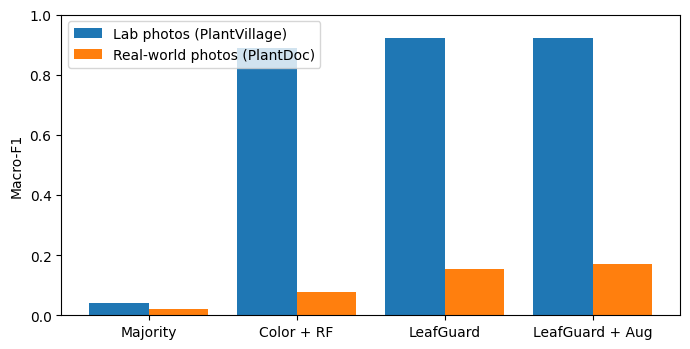

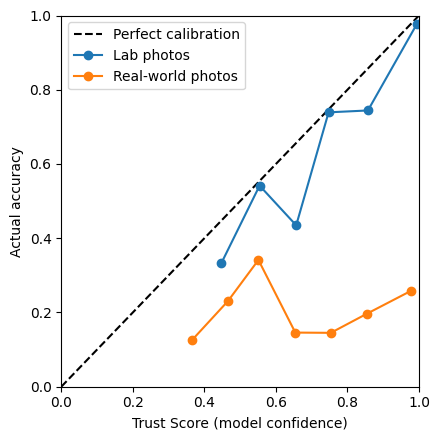

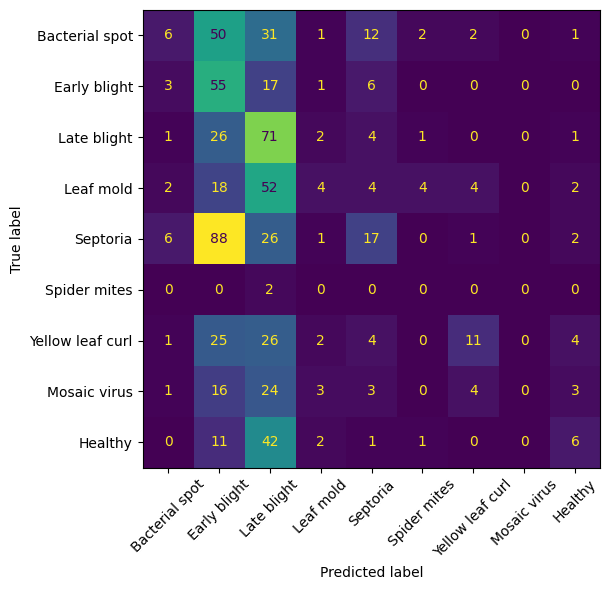

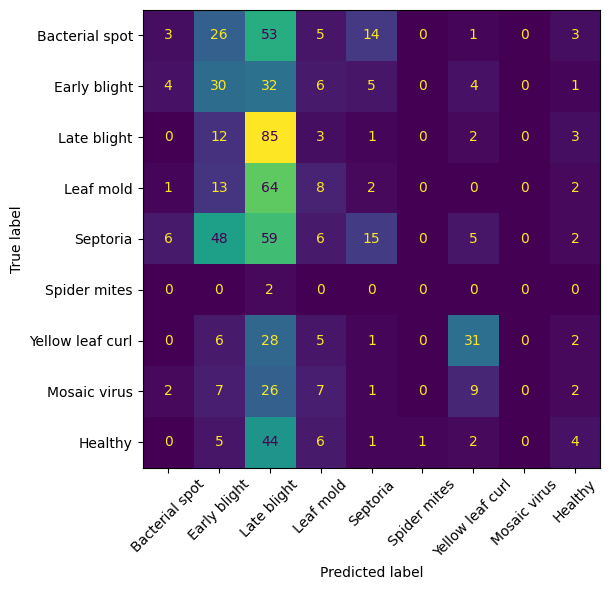

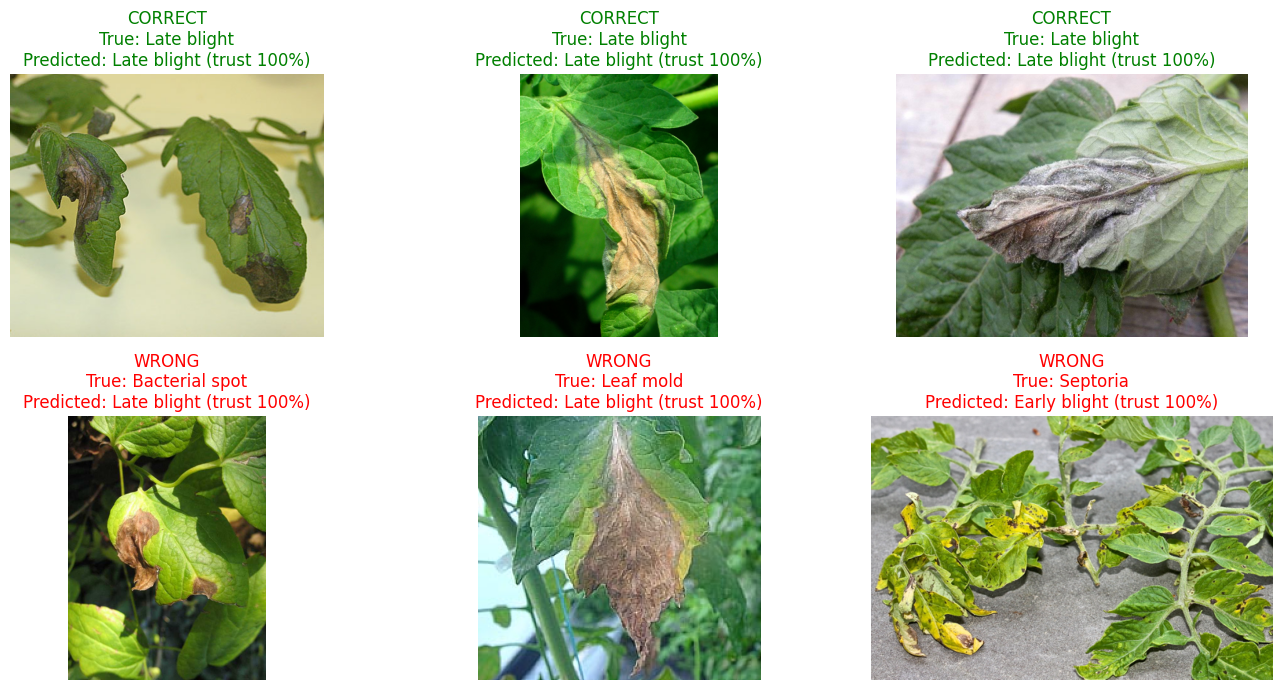

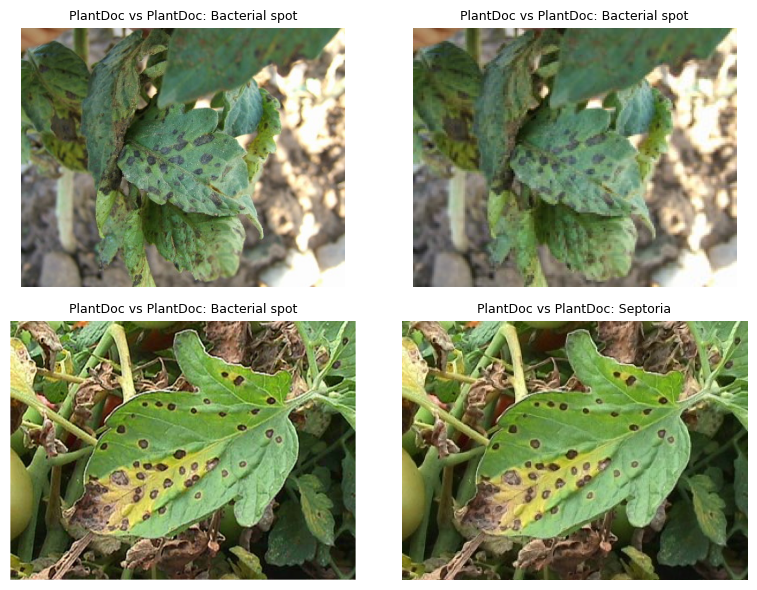

In [12]:
import os, shutil, joblib
from collections import defaultdict, Counter
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report, ConfusionMatrixDisplay

NEAR = 10  # near-duplicate: 256-bit difference hashes differ in at most 10 bits

#Exact duplicates in the raw PlantDoc folders, with labels
md5_groups = defaultdict(list)
for c in range(9):
    for p in field_raw[c]:
        md5_groups[hashlib.md5(p.read_bytes()).hexdigest()].append((c, p))
dup_groups = [v for v in md5_groups.values() if len(v) > 1]
conflicts = [v for v in dup_groups if len({c for c, _ in v}) > 1]
print("=== EXACT DUPLICATES (PlantDoc) ===")
print(f"{len(dup_groups)} duplicate groups, {len(conflicts)} with conflicting labels")
for v in conflicts:
    print("  conflicting:", [(SHORT[c], p.name) for c, p in v])

#difference hash for every image used
POP = np.array([bin(i).count('1') for i in range(256)], dtype=np.uint8)
def dhash(p, n=16):
    g = np.asarray(load(p).convert('L').resize((n + 1, n), Image.Resampling.LANCZOS), dtype=np.int16)
    return np.packbits((g[:, 1:] > g[:, :-1]).flatten())
def hamming(A, B):
    out = np.zeros((len(A), len(B)), dtype=np.uint16)
    for k in range(A.shape[1]):
        out += POP[np.bitwise_xor(A[:, k][:, None], B[:, k][None, :])]
    return out
D_tr = np.array([dhash(p) for p in train_p])
D_lt = np.array([dhash(p) for p in labtest_p])
D_fd = np.array([dhash(p) for p in field_p])

#Near-duplicates within PlantDoc: group them, then apply an explicit rule
Hff = hamming(D_fd, D_fd)
ii, jj = np.where(np.triu(Hff <= NEAR, k=1))
parent = list(range(len(field_p)))
def find(a):
    while parent[a] != a:
        parent[a] = parent[parent[a]]
        a = parent[a]
    return a
for a, b in zip(ii, jj):
    parent[find(a)] = find(b)
groups = defaultdict(list)
for k in range(len(field_p)):
    groups[find(k)].append(k)
near_groups = [sorted(g) for g in groups.values() if len(g) > 1]

drop_reason = {}
for g in near_groups:
    if len({int(y_field[k]) for k in g}) > 1:   # conflicting labels: true label unknown, drop every copy
        for k in g:
            drop_reason[k] = 'near-duplicate, conflicting labels'
    else:                                       # same label: keep one copy
        for k in g[1:]:
            drop_reason[k] = 'near-duplicate, same label'
idx_of = {str(p): k for k, p in enumerate(field_p)}
for v in conflicts:                             # surviving copy of an exact duplicate with conflicting labels
    for c, p in v:
        if str(p) in idx_of:
            drop_reason[idx_of[str(p)]] = 'exact duplicate, conflicting labels'

# Across datasets, and across the lab train/test split
Hft = hamming(D_fd, D_tr)
cross_train = np.where((Hft <= NEAR).any(axis=1))[0]
for k in cross_train:
    drop_reason.setdefault(int(k), 'near-copy of a lab training image')
cross_test = int((hamming(D_fd, D_lt) <= NEAR).any(axis=1).sum())
Hlt = hamming(D_lt, D_tr)
lab_leak = np.where((Hlt <= NEAR).any(axis=1))[0]

keep_f = np.array([k not in drop_reason for k in range(len(field_p))])
keep_l = np.ones(len(labtest_p), dtype=bool)
keep_l[lab_leak] = False

print(f"\n=== NEAR-DUPLICATE AUDIT (256-bit difference hash, at most {NEAR} bits apart) ===")
n_conf = sum(len({int(y_field[k]) for k in g}) > 1 for g in near_groups)
print(f"PlantDoc near-duplicate groups: {len(near_groups)} ({n_conf} with conflicting labels)")
for g in near_groups:
    print("  group:", [(SHORT[y_field[k]], field_p[k].name[:40]) for k in g])
print(f"PlantDoc images with a near-copy in lab TRAINING images: {len(cross_train)}")
print(f"PlantDoc images with a near-copy in lab TEST images: {cross_test}")
print(f"Lab test images with a near-copy in lab TRAINING images: {len(lab_leak)}")
print(f"Real-world images dropped: {len(drop_reason)} {dict(Counter(drop_reason.values()))}")
print(f"AUDITED TEST SETS: {keep_l.sum()} lab photos | {keep_f.sum()} real-world photos")

#Re-score the same trained models on the audited test sets
yl, yf = y_lab[keep_l], y_field[keep_f]
Fl, Ff = F_lab[keep_l], F_field[keep_f]
Hl, Hf = H_lab[keep_l], H_field[keep_f]
def evaluate(y, pred):
    return (accuracy_score(y, pred),
            f1_score(y, pred, labels=np.unique(y), average='macro', zero_division=0))
methods = {
    'Majority class (floor)':          (np.full(len(yl), majority), np.full(len(yf), majority)),
    'Color histogram + Random Forest': (rf.predict(Hl), rf.predict(Hf)),
    'LeafGuard':                       (cnn.predict(Fl), cnn.predict(Ff)),
    'LeafGuard + augmentation':        (cnn_aug.predict(Fl), cnn_aug.predict(Ff)),
}
rows = []
for name, (pl, pf) in methods.items():
    la, lf = evaluate(yl, pl)
    fa, ff = evaluate(yf, pf)
    rows.append([name, la, lf, fa, ff, np.nan if name.startswith('Majority') else ff / lf])
table_a = pd.DataFrame(rows, columns=['Method', 'Lab acc', 'Lab macro-F1', 'Real acc', 'Real macro-F1', 'FRS'])
table_a.to_csv('results_table_audited.csv', index=False)
print("\n=== TABLE 2 (AUDITED) ===")
print(table_a.round(3).to_string(index=False))

#Trust Score: calibration, ranking, and retained predictions at each threshold
print("\n=== TRUST SCORE (AUDITED) ===")
probs, thr_rows = {}, []
for name, model in [('LeafGuard', cnn), ('LeafGuard + augmentation', cnn_aug)]:
    for split, F, y in [('Lab', Fl, yl), ('Real', Ff, yf)]:
        p = model.predict_proba(F)
        c, ok = p.max(axis=1), p.argmax(axis=1) == y
        probs[(name, split)] = (p, c, ok)
        auroc = roc_auc_score(ok, c) if 0 < ok.mean() < 1 else float('nan')
        print(f"{name} | {split}: avg trust {c.mean():.3f} | accuracy {ok.mean():.3f} | "
              f"ECE {ece(c, ok):.3f} | AUROC {auroc:.3f}")
        for t in [0.0, 0.5, 0.6, 0.7, 0.8, 0.9]:
            m = c >= t
            thr_rows.append([name, split, t, int(m.sum()), m.mean(), ok[m].mean() if m.any() else np.nan])
thr = pd.DataFrame(thr_rows, columns=['Model', 'Set', 'Threshold', 'Retained', 'Share', 'Accuracy'])
thr.to_csv('trust_thresholds_audited.csv', index=False)
print("\n=== RETAINED PREDICTIONS BY TRUST THRESHOLD (AUDITED) ===")
print(thr.round(3).to_string(index=False))

#Prediction patterns and per-class results
print("\n=== REAL-WORLD PREDICTION PATTERNS (AUDITED) ===")
for name, model in [('LeafGuard', cnn), ('LeafGuard + augmentation', cnn_aug)]:
    pr = model.predict(Ff)
    print(f"{name}: {np.isin(pr, [1, 2]).sum()} of {len(pr)} ({np.isin(pr, [1, 2]).mean():.1%}) early/late blight | "
          f"healthy as late blight: {((yf == 8) & (pr == 2)).sum()} of {(yf == 8).sum()} | "
          f"Septoria as early blight: {((yf == 4) & (pr == 1)).sum()} of {(yf == 4).sum()} | "
          f"mosaic predicted {(pr == 7).sum()} times")
for name, model in [('LeafGuard', cnn), ('LeafGuard + augmentation', cnn_aug)]:
    print(f"\n=== PER-CLASS REAL-WORLD RESULTS (AUDITED): {name} ===")
    print(classification_report(yf, model.predict(Ff), labels=list(range(9)),
                                target_names=SHORT, zero_division=0, digits=3))

#Figures for the paper, rebuilt on the audited test sets
x = np.arange(len(table_a))
plt.figure(figsize=(7, 3.6))
plt.bar(x - 0.2, table_a['Lab macro-F1'], 0.4, label='Lab photos (PlantVillage)')
plt.bar(x + 0.2, table_a['Real macro-F1'], 0.4, label='Real-world photos (PlantDoc)')
plt.xticks(x, ['Majority', 'Color + RF', 'LeafGuard', 'LeafGuard + Aug'])
plt.ylabel('Macro-F1'); plt.ylim(0, 1); plt.legend()
plt.tight_layout(); plt.savefig('results_chart.png', dpi=200); plt.show()

plt.figure(figsize=(4.5, 4.5))
plt.plot([0, 1], [0, 1], 'k--', label='Perfect calibration')
for split, label in [('Lab', 'Lab photos'), ('Real', 'Real-world photos')]:
    _, c, ok = probs[('LeafGuard', split)]
    b = np.minimum((c * 10).astype(int), 9)
    keep = [i for i in range(10) if (b == i).sum() >= 5]
    plt.plot([c[b == i].mean() for i in keep], [ok[b == i].mean() for i in keep], 'o-', label=label)
plt.xlabel('Trust Score (model confidence)'); plt.ylabel('Actual accuracy')
plt.xlim(0, 1); plt.ylim(0, 1); plt.legend()
plt.tight_layout(); plt.savefig('reliability.png', dpi=200); plt.show()

for fname, model in [('field_confusion.png', cnn), ('field_confusion_aug.png', cnn_aug)]:
    fig, ax = plt.subplots(figsize=(7, 6))
    ConfusionMatrixDisplay.from_predictions(yf, model.predict(Ff), labels=list(range(9)),
                                            display_labels=SHORT, xticks_rotation=45, colorbar=False, ax=ax)
    plt.tight_layout(); plt.savefig(fname, dpi=200); plt.show()

fp_a = [p for p, k in zip(field_p, keep_f) if k]
p_lg, c, ok = probs[('LeafGuard', 'Real')]
pr = p_lg.argmax(axis=1)
right, wrong = np.where(ok)[0], np.where(~ok)[0]
pick = list(right[np.argsort(-c[right])][:3]) + list(wrong[np.argsort(-c[wrong])][:3])
plt.figure(figsize=(14, 7))
for n, k in enumerate(pick):
    plt.subplot(2, 3, n + 1)
    plt.imshow(load(fp_a[k])); plt.axis('off')
    plt.title(f"{'CORRECT' if ok[k] else 'WRONG'}\nTrue: {SHORT[yf[k]]}\nPredicted: {SHORT[pr[k]]} (trust {c[k]:.0%})",
              fontsize=12, color='green' if ok[k] else 'red')
plt.tight_layout(); plt.savefig('field_examples.png', dpi=150); plt.show()

pairs = [(field_p[g[0]], y_field[g[0]], field_p[g[1]], y_field[g[1]], 'PlantDoc vs PlantDoc') for g in near_groups[:2]]
pairs += [(field_p[k], y_field[k], train_p[int(Hft[k].argmin())], y_train[int(Hft[k].argmin())], 'PlantDoc vs lab train')
          for k in cross_train[:2]]
pairs += [(labtest_p[i], y_lab[i], train_p[int(Hlt[i].argmin())], y_train[int(Hlt[i].argmin())], 'lab test vs lab train')
          for i in lab_leak[:2]]
if pairs:
    plt.figure(figsize=(8, 3 * len(pairs)))
    for r, (pa, ya, pb, yb, kind) in enumerate(pairs):
        for col, (pp, yy) in enumerate([(pa, ya), (pb, yb)]):
            plt.subplot(len(pairs), 2, 2 * r + col + 1)
            plt.imshow(load(pp)); plt.axis('off')
            plt.title(f"{kind}: {SHORT[yy]}", fontsize=9)
    plt.tight_layout(); plt.savefig('near_duplicates.png', dpi=120); plt.show()

In [13]:
os.makedirs('artifacts', exist_ok=True)
def rel(p):
    for root in (Path(pv_path), Path('PlantDoc-Dataset')):
        try:
            return str(Path(p).relative_to(root))
        except ValueError:
            pass
    return str(p)

pd.DataFrame({'path': [rel(p) for p in train_p], 'label': [SHORT[k] for k in y_train]}
             ).to_csv('artifacts/split_lab_train.csv', index=False)
pd.DataFrame({'path': [rel(p) for p in labtest_p], 'label': [SHORT[k] for k in y_lab], 'kept_in_audit': keep_l}
             ).to_csv('artifacts/split_lab_test.csv', index=False)
pd.DataFrame({'path': [rel(p) for p in field_p], 'label': [SHORT[k] for k in y_field], 'kept_in_audit': keep_f,
              'drop_reason': [drop_reason.get(k, '') for k in range(len(field_p))]}
             ).to_csv('artifacts/split_real_world.csv', index=False)

for tag, model, Xl, Xf in [('leafguard', cnn, F_lab, F_field), ('leafguard_aug', cnn_aug, F_lab, F_field),
                           ('color_rf', rf, H_lab, H_field)]:
    for split, X, paths, y in [('lab_test', Xl, labtest_p, y_lab), ('real_world', Xf, field_p, y_field)]:
        p = model.predict_proba(X)
        df = pd.DataFrame(p, columns=[f'prob_{s}' for s in SHORT])
        df.insert(0, 'path', [rel(q) for q in paths])
        df.insert(1, 'true', [SHORT[k] for k in y])
        df.insert(2, 'pred', [SHORT[k] for k in p.argmax(axis=1)])
        df.insert(3, 'confidence', p.max(axis=1))
        df.to_csv(f'artifacts/predictions_{tag}_{split}.csv', index=False)

joblib.dump(cnn, 'artifacts/leafguard_classifier.joblib')
joblib.dump(cnn_aug, 'artifacts/leafguard_aug_classifier.joblib')
np.savez_compressed('artifacts/color_histograms.npz', H_train=H_train, y_train=y_train,
                    H_lab=H_lab, y_lab=y_lab, H_field=H_field, y_field=y_field)
for f in ['results_table.csv', 'results_table_audited.csv', 'trust_thresholds_audited.csv', 'requirements.txt']:
    if os.path.exists(f):
        shutil.copy(f, 'artifacts/')
shutil.make_archive('leafguard_artifacts', 'zip', 'artifacts')
print("Saved leafguard_artifacts.zip:", round(os.path.getsize('leafguard_artifacts.zip') / 1e6, 1), "MB")
print(sorted(os.listdir('artifacts')))

Saved leafguard_artifacts.zip: 1.4 MB
['color_histograms.npz', 'leafguard_aug_classifier.joblib', 'leafguard_classifier.joblib', 'predictions_color_rf_lab_test.csv', 'predictions_color_rf_real_world.csv', 'predictions_leafguard_aug_lab_test.csv', 'predictions_leafguard_aug_real_world.csv', 'predictions_leafguard_lab_test.csv', 'predictions_leafguard_real_world.csv', 'requirements.txt', 'results_table.csv', 'results_table_audited.csv', 'split_lab_test.csv', 'split_lab_train.csv', 'split_real_world.csv', 'trust_thresholds_audited.csv']
